## 1. Setup and Data Generation

First, let's import the necessary libraries and generate mock single-cell data with cell types.


In [1]:
import sys
import numpy as np
import pandas as pd
import scanpy as sc
import anndata
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Add the mock_data module to path
mock_data_path = "/home/converge-bio/virtual-cell/virtual_cell/patient/src/explainability"
if mock_data_path not in sys.path:
    sys.path.append(mock_data_path)

from mock_data import mock_dataset_with_cell_types, get_cell_type_info

# Add B2SC to path and import components
b2sc_path = "/home/converge-bio/B2SC"
if b2sc_path not in sys.path:
    sys.path.append(b2sc_path)

# Import B2SC components directly
from config import B2SCConfig
from pipeline import B2SCPipeline
from data_manager import DataManager
from gmvae_trainer import GMVAETrainer
from bulk_encoder_trainer import BulkEncoderTrainer
from utilities import calculate_pseudobulk

# Set up plotting
plt.style.use('default')
sns.set_palette("husl")

print("✅ All imports successful!")


✅ All imports successful!


### Generate Mock Single-Cell Data

We'll create a realistic single-cell dataset with:
- 200 samples (donors)
- 500 cells per sample
- 2000 genes
- 4 cell types with different proportions


In [2]:
# Parameters for mock data generation
n_samples = 200
n_cells = 500
n_genes = 500
random_seed = 42

# Define cell type proportions
cell_type_proportions = {0: {"T_cell": 0.25, 
                            "B_cell": 0.75, 
                            # "NK_cell" : 0.2, 
                            # "Activated_T_cell": 0.05
                            }, 
                        1: {"T_cell": 0.6, 
                            "B_cell": 0.4, 
                            # "NK_cell" : 0.1, 
                            # "Activated_T_cell": 0.2
                            }}

# Define differential gene expression patterns for each class
# Class 0: Control samples, Class 1: Disease samples
differential_genes_per_class = [
    {  # Class 0 (Control)
        "T_cell": {10: 0.5, 25: 0.7, 50: 0.6},  # Lower expression
        "B_cell": {100: 0.4, 150: 0.8, 200: 3},
        # "NK_cell": {300: 0.6, 350: 0.7, 400: 0.4},
    },
    # {  # Class 1 (Disease)
    #     "T_cell": {10: 2.0, 25: 1.8, 50: 2.2},  # Higher expression
    #     "B_cell": {100: 2.5, 150: 0.01, 200: 2.0},
    #     # "NK_cell": {300: 1.8, 350: 1.6, 400: 2.1},
    # }
    {  # Class 1 (Same)
        "T_cell": {10: 0.5, 25: 0.7, 50: 0.6},  # Lower expression
        "B_cell": {100: 0.4, 150: 0.8, 200: 3},
        # "NK_cell": {300: 0.6, 350: 0.7, 400: 0.4},
    }

]

print("Generating mock single-cell data...")
X, y, cell_types = mock_dataset_with_cell_types(
    n_samples=n_samples,
    n_cells=n_cells,
    n_genes=n_genes,
    cell_type_proportions=cell_type_proportions,
    differential_genes_per_class=differential_genes_per_class,
    random_seed=random_seed,
    zero_inflation=0.6,
    num_classes=2
)

print(f"Generated data shape: {X.shape}")
print(f"Labels shape: {y.shape}")
print(f"Cell types shape: {cell_types.shape}")
print(f"Class distribution: {np.bincount(y)}")


Generating mock single-cell data...
Generated data shape: (200, 500, 500)
Labels shape: (200,)
Cell types shape: (200, 500)
Class distribution: [100 100]


### Convert to AnnData Format

We'll convert the mock data to AnnData format for compatibility with the B2SC pipeline.


In [3]:
# Reshape data: (n_samples, n_cells, n_genes) -> (n_samples * n_cells, n_genes)
X_reshaped = X.reshape(-1, n_genes)
print(f"Reshaped data: {X_reshaped.shape}")

# Create cell and gene names
cell_names = [f"sample_{i}_cell_{j}" for i in range(n_samples) for j in range(n_cells)]
gene_names = [f"gene_{i}" for i in range(n_genes)]

# Create donor IDs and sample labels for each cell
donor_ids = [f"donor_{i}" for i in range(n_samples) for _ in range(n_cells)]
sample_labels = [y[i] for i in range(n_samples) for _ in range(n_cells)]

# Flatten cell types
cell_types_flat = cell_types.flatten()

# Map cell type indices to names
# Handle both class-specific and global proportions
if isinstance(list(cell_type_proportions.values())[0], dict):
    # Class-specific proportions: extract cell type names from first class
    cell_type_names = sorted(list(cell_type_proportions[0].keys()))
else:
    # Global proportions: use keys directly
    cell_type_names = list(cell_type_proportions.keys())

cell_type_labels = [cell_type_names[ct] for ct in cell_types_flat]

# Create AnnData object
adata = anndata.AnnData(
    X=X_reshaped,
    obs=pd.DataFrame({
        'donor_id': donor_ids,
        'cell_type': cell_type_labels,
        'sample_label': sample_labels
    }, index=cell_names),
    var=pd.DataFrame(index=gene_names)
)

print(f"AnnData object created: {adata.shape}")
print(f"Observations: {list(adata.obs.columns)}")
print(f"Cell type distribution:")
print(adata.obs['cell_type'].value_counts())


Reshaped data: (100000, 500)
AnnData object created: (100000, 500)
Observations: ['donor_id', 'cell_type', 'sample_label']
Cell type distribution:
cell_type
B_cell    57347
T_cell    42653
Name: count, dtype: int64


## 2. Data Splitting

We'll split the data into training (80%), validation (10%), and test (10%) sets at the donor level to ensure no data leakage.


In [4]:
# # Normalize and log-transform the data
# print("Normalizing and log-transforming data...")

# # Store raw counts
# adata.raw = adata

# # Normalize to 10,000 reads per cell
# sc.pp.normalize_total(adata, target_sum=1e4)

# # Log transform (log1p)
# sc.pp.log1p(adata)

# print(f"Data normalized and log-transformed")
# print(f"Data range after normalization: [{adata.X.min():.3f}, {adata.X.max():.3f}]")


In [5]:
# Get unique donors and their labels
donor_info = adata.obs.groupby('donor_id')['sample_label'].first().reset_index()
unique_donors = donor_info['donor_id'].values
donor_labels = donor_info['sample_label'].values

print(f"Total donors: {len(unique_donors)}")
print(f"Donor label distribution: {np.bincount(donor_labels)}")


Total donors: 200
Donor label distribution: [100 100]


In [6]:
# Split donors into train/val/test (80/10/10)
# First split: 80% train, 20% temp
train_donors, temp_donors, train_labels, temp_labels = train_test_split(
    unique_donors, donor_labels, 
    test_size=0.2, 
    random_state=random_seed, 
    stratify=donor_labels
)

# Second split: 10% val, 10% test from the 20% temp
val_donors, test_donors, val_labels, test_labels = train_test_split(
    temp_donors, temp_labels, 
    test_size=0.5, 
    random_state=random_seed, 
    stratify=temp_labels
)

print(f"\nSplit sizes:")
print(f"Train donors: {len(train_donors)} ({len(train_donors)/len(unique_donors)*100:.1f}%)")
print(f"Val donors: {len(val_donors)} ({len(val_donors)/len(unique_donors)*100:.1f}%)")
print(f"Test donors: {len(test_donors)} ({len(test_donors)/len(unique_donors)*100:.1f}%)")

# Create boolean masks for each split
train_mask = adata.obs['donor_id'].isin(train_donors)
val_mask = adata.obs['donor_id'].isin(val_donors)
test_mask = adata.obs['donor_id'].isin(test_donors)

# Create split datasets
adata_train = adata[train_mask].copy()
adata_val = adata[val_mask].copy()
adata_test = adata[test_mask].copy()

print(f"\nDataset sizes:")
print(f"Train: {adata_train.shape[0]:,} cells from {adata_train.obs['donor_id'].nunique()} donors")
print(f"Val: {adata_val.shape[0]:,} cells from {adata_val.obs['donor_id'].nunique()} donors")
print(f"Test: {adata_test.shape[0]:,} cells from {adata_test.obs['donor_id'].nunique()} donors")



Split sizes:
Train donors: 160 (80.0%)
Val donors: 20 (10.0%)
Test donors: 20 (10.0%)

Dataset sizes:
Train: 80,000 cells from 160 donors
Val: 10,000 cells from 20 donors
Test: 10,000 cells from 20 donors


In [7]:
output_dir = Path("/home/converge-bio/B2SC/examples/tutorial_outputs")

In [8]:
# Save the training data
output_dir.mkdir(parents=True, exist_ok=True)

print("Saving training data...")
adata_train.write_h5ad(output_dir / "train_data.h5ad")
print(f"✅ Training data saved to: {output_dir / 'train_data.h5ad'}")

# Also save validation and test data for completeness
adata_val.write_h5ad(output_dir / "val_data.h5ad")
adata_test.write_h5ad(output_dir / "test_data.h5ad")
print(f"✅ Validation data saved to: {output_dir / 'val_data.h5ad'}")
print(f"✅ Test data saved to: {output_dir / 'test_data.h5ad'}")


Saving training data...
✅ Training data saved to: /home/converge-bio/B2SC/examples/tutorial_outputs/train_data.h5ad
✅ Validation data saved to: /home/converge-bio/B2SC/examples/tutorial_outputs/val_data.h5ad
✅ Test data saved to: /home/converge-bio/B2SC/examples/tutorial_outputs/test_data.h5ad


## Configure the Training Parameters

In [9]:
# Set model-specific hyperparameters using the new hierarchical structure
#config.gmvae_hyperparameters.update({
#    "hidden_dim": 64,
#    "epochs": 30,  # Fewer epochs for tutorial
#    "use_layer_norm": True,  
#    "batch_size": 4,
#    "fraction_loss_weight": 10000.0, #10.0,
#    "learning_rate": 1e-4,
#    "recon_warmup_midpoint" : 3,
#    "recon_warmup_steepness" : 2.2,
#  "kl_loss_weight" : 0.1, #10,
#   'zinb_loss_weight' : 1.0, #100.0,
#})

In [ ]:
# Configure B2SC pipeline
config = B2SCConfig(
    sc_training_path=str(output_dir / "train_data.h5ad"),
    sc_validation_path=str(output_dir / "val_data.h5ad"),  # Use validation data
    pseudobulk_groupby="donor_id",  # Group by donor for pseudobulk computation
    cache_pseudobulk=False,  # Enable caching for faster reruns
    base_dir=str(output_dir / "results"),
    latent_dim=32,
    device="auto"
)

config.gmvae_hyperparameters.update({
    'kl_scale_divisor': 1e8,        # Was 1 - this is THE critical fix
    'kl_loss_weight': 0.01,         # Was 0.1
    'kl_anneal_max': 0.1,           # Was 1.0
    
    'fraction_loss_weight': 10.0,   # Was 10000 - way too high!
    'recon_loss_weight': 2.0,      # Increase reconstruction importance
    'zinb_loss_weight': 1000.0,       # Increase ZINB importance
    
    'learning_rate': 1e-5,          # Was 1e-4 - more stable
    'batch_size': 8,
    'epochs': 10,
})
config.bulk_encoder_hyperparameters.update({
    "hidden_dim": 64,
    "epochs": 30,
    "learning_rate": 1e-5,
    "pis_loss_weight" : 100.0,
    "logvars_loss_weight" : 1e-4,
    "mus_loss_weight" : 1e-4,
    'uniform_penalty_weight' : 10.0

})

print(f"Configuration:")
print(f"  Training data: {config.sc_training_path}")
print(f"  Validation data: {config.sc_validation_path}")
print(f"  Pseudobulk groupby: {config.pseudobulk_groupby}")
print(f"  Cache enabled: {config.cache_pseudobulk}")
print(f"  Hidden dim: {config.hidden_dim}")
print(f"  Latent dim: {config.latent_dim}")
print(f"  GMVAE epochs: {config.gmvae_epochs}")
print(f"  BulkEncoder epochs: {config.bulk_encoder_epochs}")
print(f"  Device: {config.device}")
print(f"\nGMVAE hyperparameters: {config.gmvae_hyperparameters}")
print(f"BulkEncoder hyperparameters: {config.bulk_encoder_hyperparameters}")


Configuration:
  Training data: /home/converge-bio/B2SC/examples/tutorial_outputs/train_data.h5ad
  Validation data: /home/converge-bio/B2SC/examples/tutorial_outputs/val_data.h5ad
  Pseudobulk groupby: donor_id
  Cache enabled: False
  Hidden dim: 2048
  Latent dim: 32
  GMVAE epochs: 30
  BulkEncoder epochs: 30
  Device: auto

GMVAE hyperparameters: {'hidden_dim': 2048, 'use_weight_norm': False, 'epochs': 30, 'learning_rate': 1e-05, 'batch_size': 4, 'recon_loss_weight': 10.0, 'zinb_loss_weight': 10.0, 'fraction_loss_weight': 10.0, 'kl_loss_weight': 0.01, 'kl_scale_divisor': 100000000.0, 'kl_clamp_max': 1000.0, 'kl_anneal_start': 0.0, 'kl_anneal_max': 0.1, 'kl_anneal_epochs': None, 'recon_warmup_steepness': 2.0, 'recon_warmup_midpoint': 3.5}
BulkEncoder hyperparameters: {'hidden_dim': 64, 'epochs': 30, 'learning_rate': 1e-05, 'batch_size': 3, 'mus_loss_weight': 0.0001, 'logvars_loss_weight': 0.0001, 'pis_loss_weight': 100.0, 'uniform_penalty_weight': 10.0, 'use_dynamic_targets': True}

## 3. GMVAE Training

Now we'll train the Gaussian Mixture Variational Autoencoder (GMVAE) on the single-cell training data.


In [11]:
config.__dict__

{'sc_training_path': '/home/converge-bio/B2SC/examples/tutorial_outputs/train_data.h5ad',
 'sc_validation_path': '/home/converge-bio/B2SC/examples/tutorial_outputs/val_data.h5ad',
 'bulk_data_for_deconv_path': None,
 'barcode_path': None,
 'pseudobulk_groupby': 'donor_id',
 'cache_pseudobulk': False,
 'input_dim': None,
 'latent_dim': 32,
 'gmvae_hyperparameters': {'hidden_dim': 2048,
  'use_weight_norm': False,
  'epochs': 30,
  'learning_rate': 1e-05,
  'batch_size': 4,
  'recon_loss_weight': 10.0,
  'zinb_loss_weight': 10.0,
  'fraction_loss_weight': 10.0,
  'kl_loss_weight': 0.01,
  'kl_scale_divisor': 100000000.0,
  'kl_clamp_max': 1000.0,
  'kl_anneal_start': 0.0,
  'kl_anneal_max': 0.1,
  'kl_anneal_epochs': None,
  'recon_warmup_steepness': 2.0,
  'recon_warmup_midpoint': 3.5},
 'bulk_encoder_hyperparameters': {'hidden_dim': 64,
  'epochs': 30,
  'learning_rate': 1e-05,
  'batch_size': 3,
  'mus_loss_weight': 0.0001,
  'logvars_loss_weight': 0.0001,
  'pis_loss_weight': 100.0,


In [12]:
# Initialize pipeline
print("Initializing B2SC pipeline...")
pipeline = B2SCPipeline(config)

print(f"✅ Pipeline initialized")

print(f"Training data file exists: {Path(config.sc_training_path).exists()}")
print(f"Validation data file exists: {Path(config.sc_validation_path).exists() if config.sc_validation_path else 'No validation path'}")


Initializing B2SC pipeline...
Using 1 GPU(s)
Using 1 GPU(s)
B2SC Pipeline initialized
✅ Pipeline initialized
Training data file exists: True
Validation data file exists: True


2025-11-11 11:15:15,000 - B2SCPipeline - INFO - Starting GMVAE training...
2025-11-11 11:15:15,000 - B2SCPipeline - INFO - Loading training data...



TRAINING GMVAE
Loading single-cell data...
Loading training data from: /home/converge-bio/B2SC/examples/tutorial_outputs/train_data.h5ad


/home/converge-bio/B2SC/utilities/helpers.py:238: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pseudobulk_df = df.groupby(groupby_col).sum()
/home/converge-bio/B2SC/utilities/helpers.py:238: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pseudobulk_df = df.groupby(groupby_col).sum()
2025-11-11 11:15:15,372 - B2SCPipeline - INFO - Training data loaded successfully


Loading validation data from: /home/converge-bio/B2SC/examples/tutorial_outputs/val_data.h5ad
Computing pseudobulk data for train (groupby: donor_id)...
Computing pseudobulk data for validation (groupby: donor_id)...
Extracted metadata: 500 genes, 2 cell types
Applied cell type encoding to 10000 cells
✅ Data loading completed
📊 GMVAE Data Dimensions:
   Number of donors in batch: 4
   Cells per donor: [500, 500, 500, 500]
   Total cells in batch: 2000
   Data shape: torch.Size([2000, 500])
   cell_type_labels shape: torch.Size([2000])
✅ Dimension validation passed!
🧬 Initializing GMVAE model...
Initializing GaussianMixtureVAE with input_dim: 500 hidden_dim: 2048 latent_dim: 32 n_components: 2
🆕 Initializing GMVAE with fresh weights (default behavior)
🎲 Initialized GMVAE with Xavier normal weights
  🧹 Cleaned up old reconstruction distribution plots


GMVAE Training:   0%|          | 0/30 [00:00<?, ?epoch/s]

...

Epoch finished
  Validation dataloader has 5 batches


GMVAE Training:  97%|█████████▋| 29/30 [10:52<00:19, 19.75s/epoch, Train Loss=1.728e+03, Recon=1.631e+03, KL=3.098e-09, Val Loss=1.726e+03]

  Validation Averages (over 5 batches):
    Total Loss: 1725.6576
    Reconstruction Loss: 162.9397
    KL Loss: 0.0000
    Fraction Loss: 0.0008
    ZINB Loss: 9.6252
    Reconstruction Correlation: 0.0472
Saving final results to folder: /home/converge-bio/B2SC/examples/tutorial_outputs/results
GMVAE Model saved.
Extracting and saving GMVAE parameters...
Loading single-cell data...
Loading training data from: /home/converge-bio/B2SC/examples/tutorial_outputs/train_data.h5ad
Loading validation data from: /home/converge-bio/B2SC/examples/tutorial_outputs/val_data.h5ad
Computing pseudobulk data for train (groupby: donor_id)...
Computing pseudobulk data for validation (groupby: donor_id)...
Extracted metadata: 500 genes, 2 cell types
Applied cell type encoding to 10000 cells
✅ Data loading completed
📊 GMVAE Data Dimensions:
   Number of donors in batch: 4
   Cells per donor: [500, 500, 500, 500]
   Total cells in batch: 2000
   Data shape: torch.Size([2000, 500])
   cell_type_labels shape

/home/converge-bio/B2SC/utilities/helpers.py:238: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pseudobulk_df = df.groupby(groupby_col).sum()
/home/converge-bio/B2SC/utilities/helpers.py:238: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pseudobulk_df = df.groupby(groupby_col).sum()


Saving mus, logvars, and pis to folder: /home/converge-bio/B2SC/examples/tutorial_outputs/results
GMVAE mus, logvars, and pis saved.
🔍 Verifying GMVAE loss calculations...
✅ Epoch 1: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 2: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 3: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 4: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 5: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 6: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 7: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 8: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 9: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 10: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 11: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 12: Total loss matches sum of weighted component

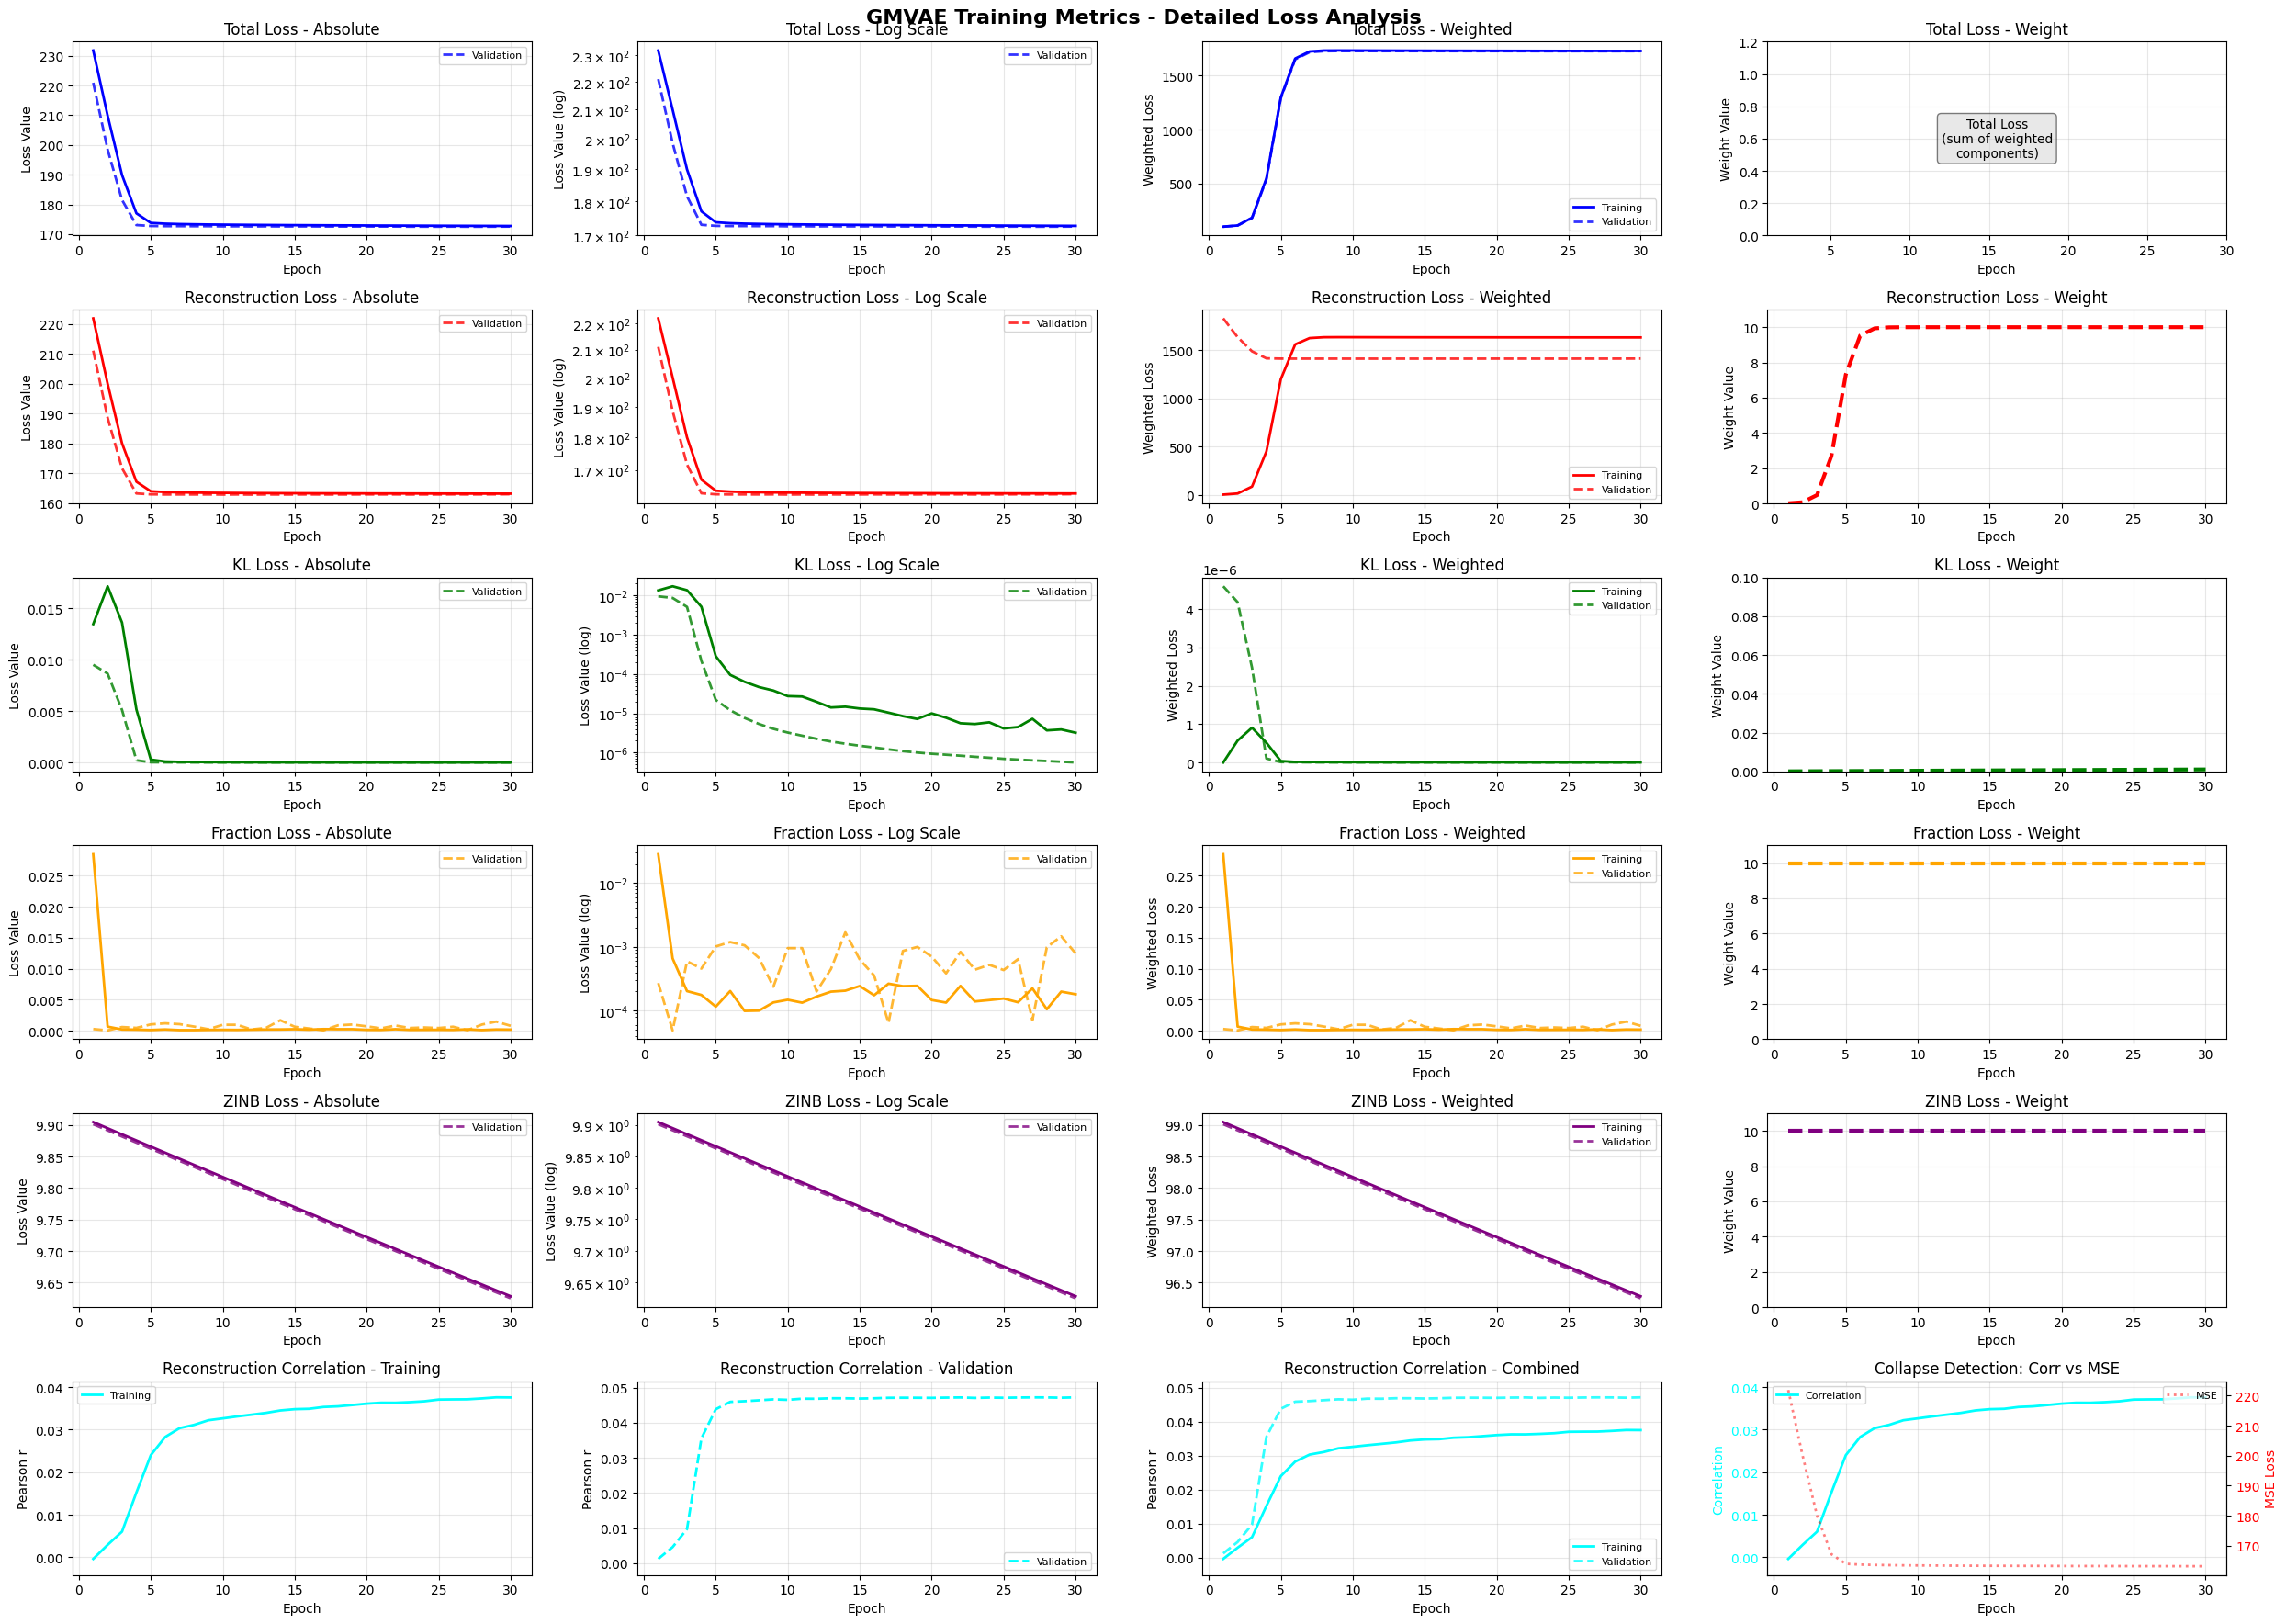

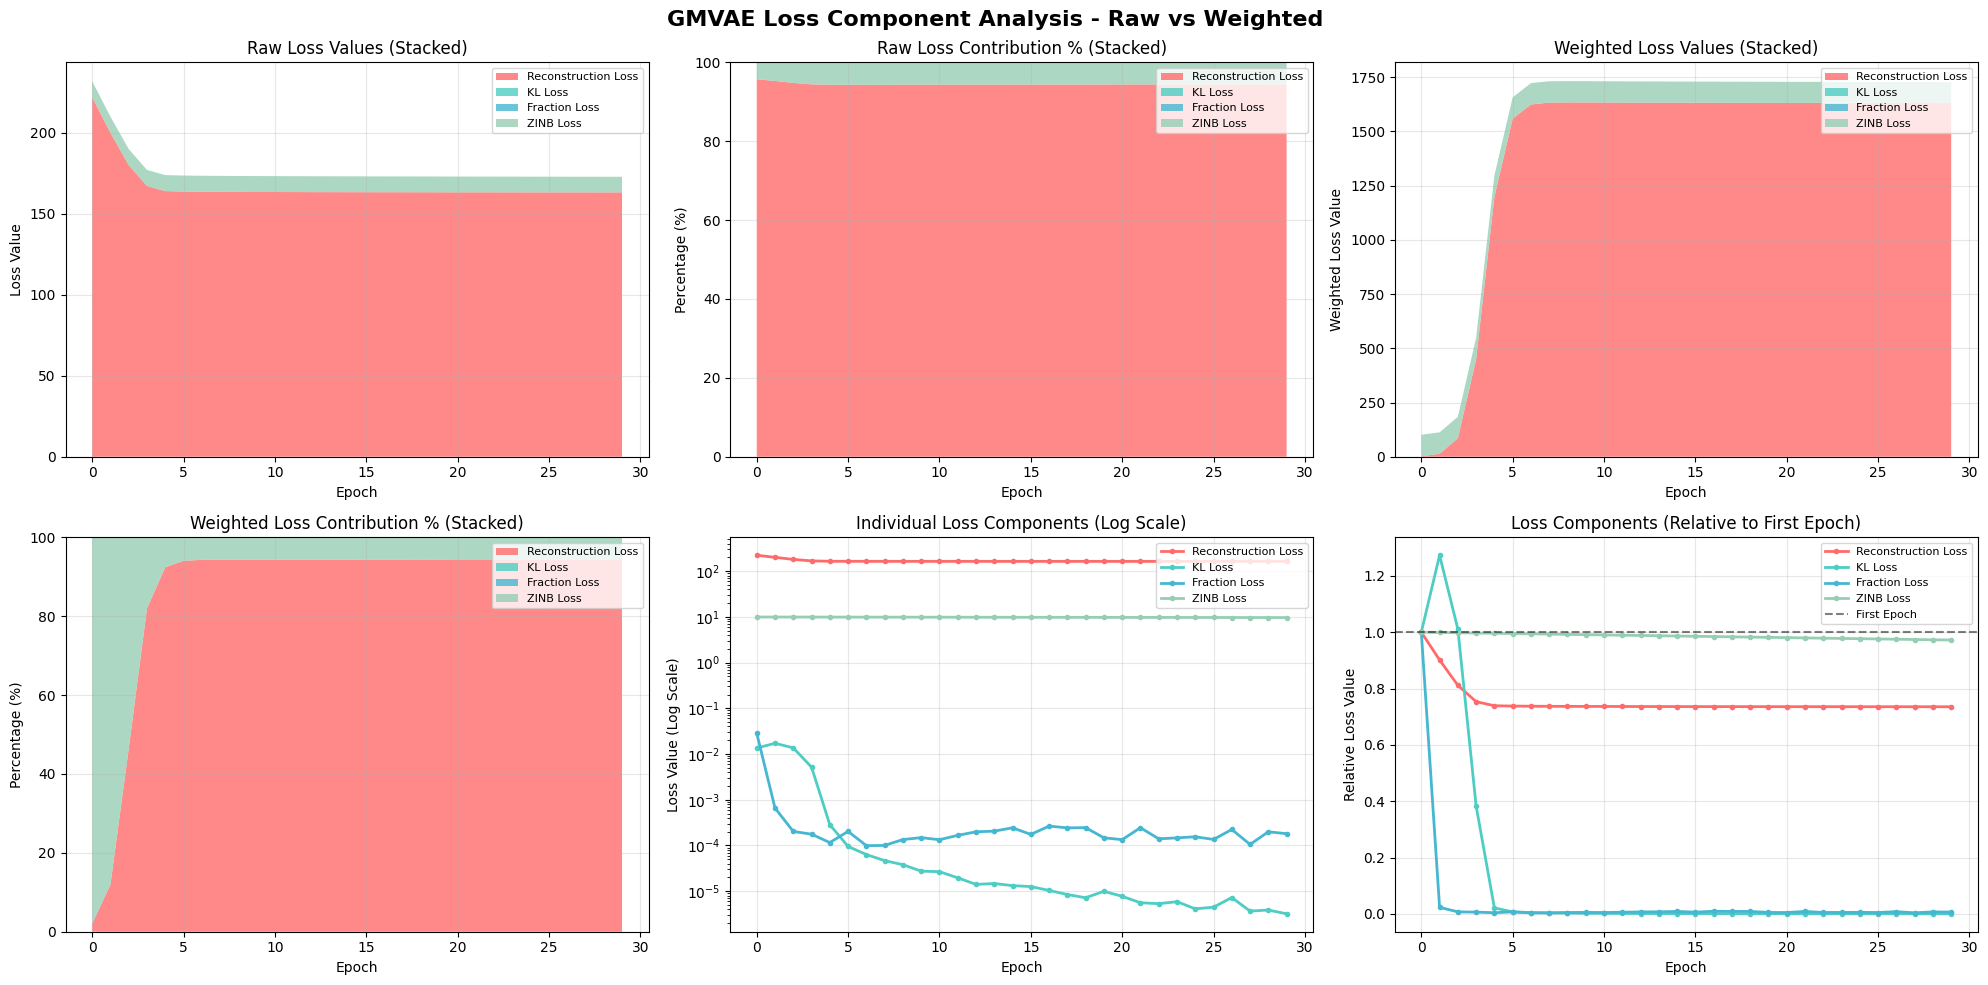

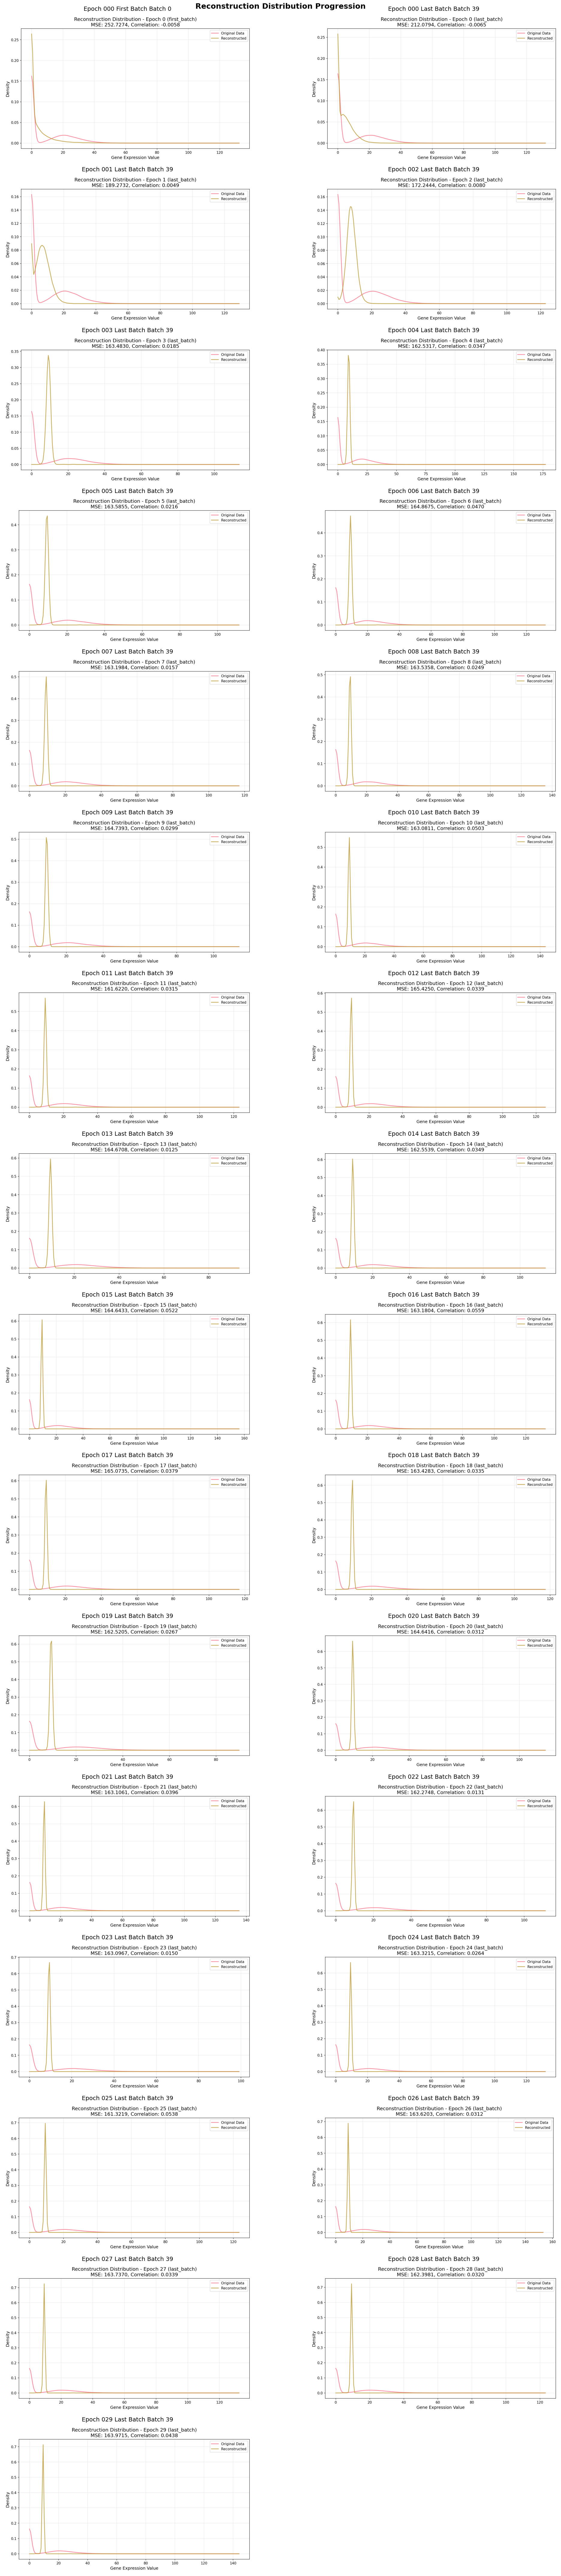

GMVAE Training: 100%|██████████| 30/30 [11:16<00:00, 22.56s/epoch, Train Loss=1.728e+03, Recon=1.631e+03, KL=3.098e-09, Val Loss=1.726e+03]
2025-11-11 11:26:32,971 - B2SCPipeline - INFO - GMVAE training completed successfully


  📊 Saved reconstruction summary: reconstruction_distribution_summary.png


In [13]:
# Train GMVAE
print("\n" + "="*50)
print("TRAINING GMVAE")
print("="*50)

gmvae_metrics = pipeline.train_gmvae()


## 4. BulkEncoder Training

Now we'll train the BulkEncoder to predict single-cell distribution parameters from bulk data.


2025-11-11 11:26:32,996 - B2SCPipeline - INFO - Starting BulkEncoder training...



TRAINING BULK ENCODER
🔬 Initializing BulkEncoder model...
Initializing bulkEncoder with input_dim: 500 hidden_dim: 64 latent_dim: 32 n_components: 2
🆕 Initializing BulkEncoder with fresh weights (default behavior)
🎲 Initialized BulkEncoder with Xavier normal weights

BulkEncoder Summary:
  Total parameters: 26,594
  Trainable parameters: 26,594
  Non-trainable parameters: 0
  Model size: 0.10 MB
BulkEncoder model initialized
Loading scMus, scLogVars, and scPis from /home/converge-bio/B2SC/examples/tutorial_outputs/results
Loaded GMVAE parameters:
  scMus shape: torch.Size([2, 32])
  scLogVars shape: torch.Size([2, 32])
  scPis shape: torch.Size([2])
🔒 Freezing GMVAE for dynamic target generation...
Using dynamic targets for BulkEncoder training...
✅ GMVAE frozen (eval mode, no gradients)


BulkEncoder Training:   3%|▎         | 1/30 [00:00<00:14,  1.97epoch/s, Train Loss=4.197e+04, Mus=2.044e+04, LogVars=2.020e+04, Pis=9.498e+02, Uniform=3.818e+02, Val Loss=5.564e+02]

Epoch[1/30]: mus_loss:3038381.500, vars_loss:2914624.500, pis_loss:0.145


BulkEncoder Training:   7%|▋         | 2/30 [00:00<00:13,  2.11epoch/s, Train Loss=2.827e+04, Mus=1.357e+04, LogVars=1.340e+04, Pis=9.145e+02, Uniform=3.822e+02, Val Loss=3.974e+02]

...

Epoch[28/30]: mus_loss:9467.903, vars_loss:7306.617, pis_loss:0.138


BulkEncoder Training:  97%|█████████▋| 29/30 [00:12<00:00,  2.31epoch/s, Train Loss=1.421e+03, Mus=6.626e+01, LogVars=7.662e+01, Pis=8.963e+02, Uniform=3.820e+02, Val Loss=2.499e+01]

Epoch[29/30]: mus_loss:25644.564, vars_loss:28392.951, pis_loss:0.200


BulkEncoder Training:  97%|█████████▋| 29/30 [00:13<00:00,  2.31epoch/s, Train Loss=1.408e+03, Mus=6.326e+01, LogVars=7.554e+01, Pis=8.873e+02, Uniform=3.818e+02, Val Loss=2.464e+01]

Epoch[30/30]: mus_loss:5572.056, vars_loss:7402.628, pis_loss:0.194
Saving last checkpoint of bulkEncoder model...
🔍 Verifying BulkEncoder loss calculations...
✅ Epoch 1: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 2: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 3: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 4: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 5: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 6: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 7: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 8: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 9: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 10: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 11: Total loss matches sum of weighted components (diff: 0.0%)
✅ Epoch 12: Total loss matches sum of weighted components (diff: 0.0

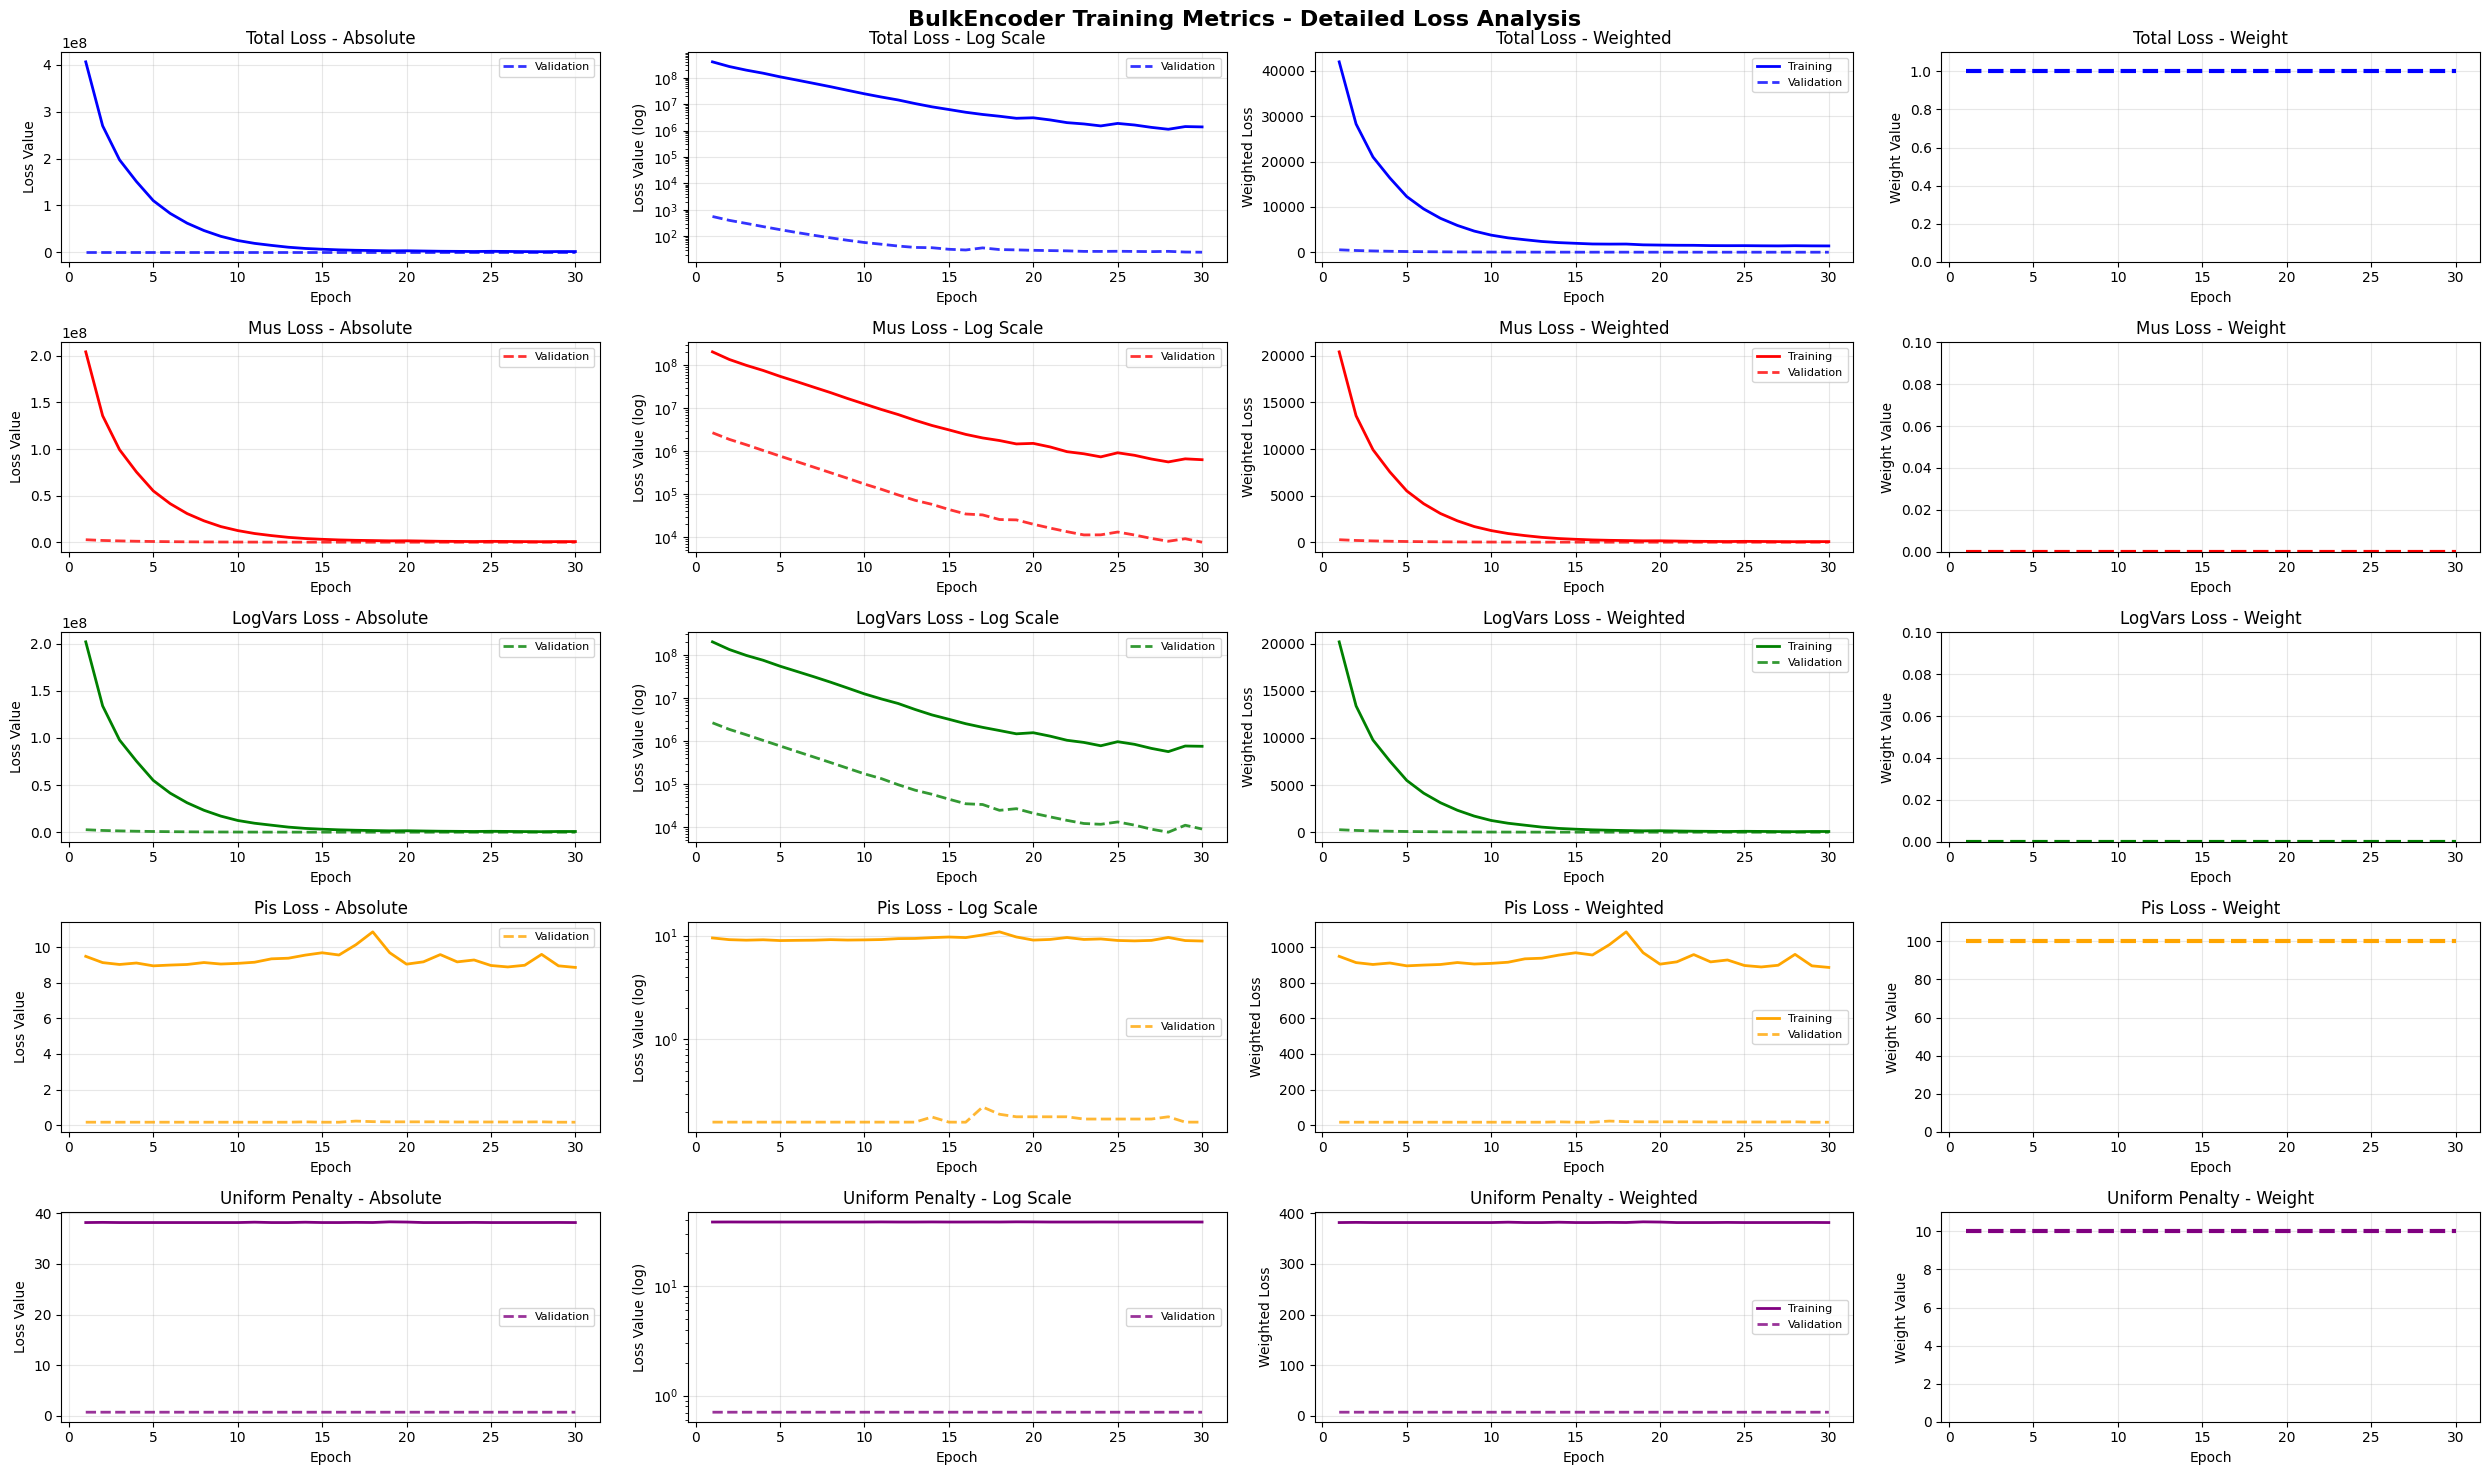

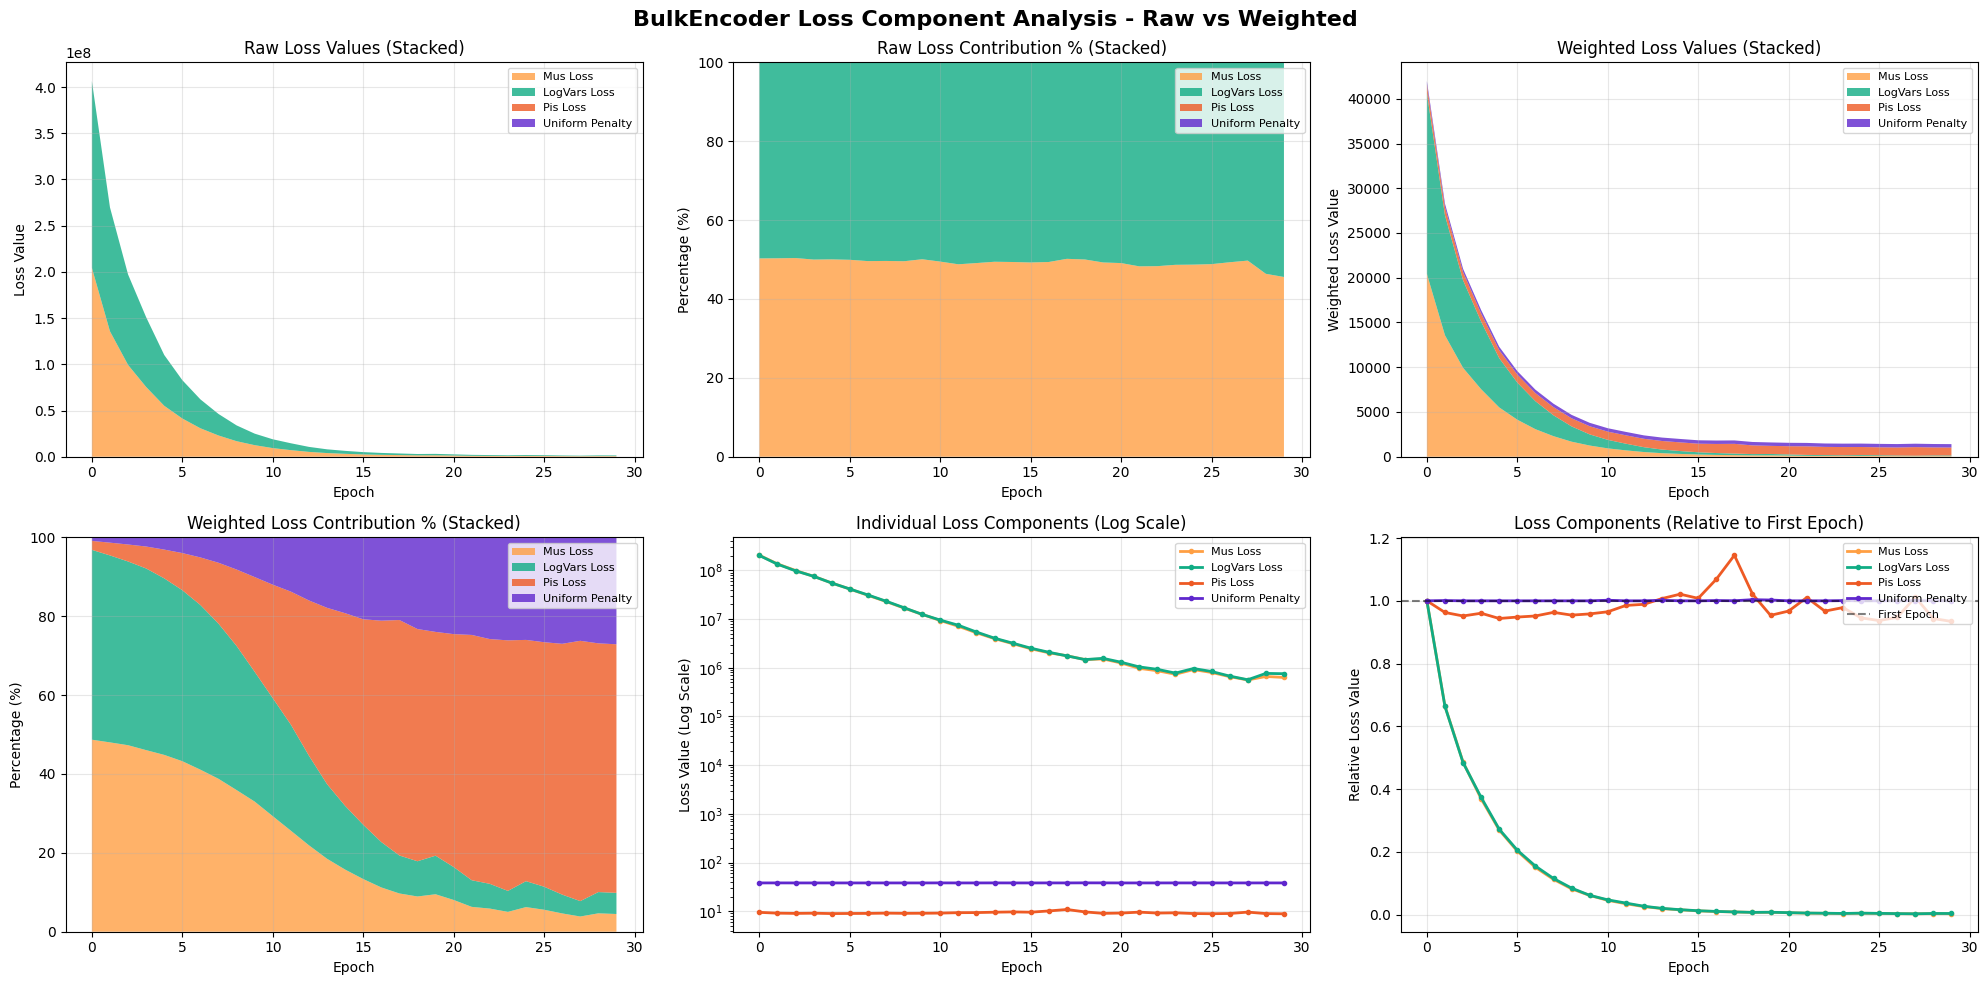

BulkEncoder Training: 100%|██████████| 30/30 [00:20<00:00,  1.49epoch/s, Train Loss=1.408e+03, Mus=6.326e+01, LogVars=7.554e+01, Pis=8.873e+02, Uniform=3.818e+02, Val Loss=2.464e+01]
2025-11-11 11:26:53,173 - B2SCPipeline - INFO - BulkEncoder training completed successfully


🔓 Unfreezing GMVAE after training...
✅ GMVAE unfrozen (train mode, gradients enabled)

✅ BulkEncoder training completed!
Total epochs: 30
Final loss: 1407.9795


In [14]:
# Train BulkEncoder
print("\n" + "="*50)
print("TRAINING BULK ENCODER")
print("="*50)

be_metrics = pipeline.train_bulk_encoder()

print(f"\n✅ BulkEncoder training completed!")
print(f"Total epochs: {len(be_metrics.history)}")
if be_metrics.history:
    final_metrics = be_metrics.history[-1]
    print(f"Final loss: {final_metrics.total_loss:.4f}")


### Represent the bulk samples of the Training Set

In [15]:
# After training both GMVAE and BulkEncoder
result = pipeline.visualize_deconvolution_comparison(
    save_path="deconvolution_comparison.png",
    max_samples_per_split=20,  # Adjust as needed
    dim_reduction_method="PCA"
)

   Using PCA for dimensionality reduction...
🔬 Generating deconvolution comparison visualization...
   Loading GMVAE model...
Initializing GaussianMixtureVAE with input_dim: 500 hidden_dim: 2048 latent_dim: 32 n_components: 2
Cell type distribution (proportions): {0: 1.0}
   Donor donor_58 class label: 0
Cell type distribution (proportions): {0: 1.0}
   Donor donor_128 class label: 1
Cell type distribution (proportions): {0: 1.0}
   Donor donor_87 class label: 0
Cell type distribution (proportions): {0: 1.0}
   Donor donor_37 class label: 0
Cell type distribution (proportions): {0: 1.0}
   Donor donor_199 class label: 0
Cell type distribution (proportions): {0: 1.0}
   Donor donor_72 class label: 0
Cell type distribution (proportions): {0: 1.0}
   Donor donor_154 class label: 1
Cell type distribution (proportions): {0: 1.0}
   Donor donor_56 class label: 0
Cell type distribution (proportions): {0: 1.0}
   Donor donor_78 class label: 1
Cell type distribution (proportions): {0: 1.0}
   D


📊 Deconvolution Comparison Summary:
   Training sample pairs: 20
   Validation sample pairs: 20
   PCA variance explained (2D): 57.2%


In [16]:
# After training both GMVAE and BulkEncoder
result = pipeline.visualize_deconvolution_comparison(
    save_path="deconvolution_comparison.png",
    max_samples_per_split=20,  # Adjust as needed
    dim_reduction_method="UMAP"
)

   Using UMAP for dimensionality reduction...
🔬 Generating deconvolution comparison visualization...
   Loading GMVAE model...
Initializing GaussianMixtureVAE with input_dim: 500 hidden_dim: 2048 latent_dim: 32 n_components: 2
Cell type distribution (proportions): {0: 1.0}
   Donor donor_58 class label: 0
Cell type distribution (proportions): {0: 1.0}
   Donor donor_128 class label: 1
Cell type distribution (proportions): {0: 1.0}
   Donor donor_87 class label: 0
Cell type distribution (proportions): {0: 1.0}
   Donor donor_37 class label: 0
Cell type distribution (proportions): {0: 1.0}
   Donor donor_199 class label: 0
Cell type distribution (proportions): {0: 1.0}
   Donor donor_72 class label: 0
Cell type distribution (proportions): {0: 1.0}
   Donor donor_154 class label: 1
Cell type distribution (proportions): {0: 1.0}
   Donor donor_56 class label: 0
Cell type distribution (proportions): {0: 1.0}
   Donor donor_78 class label: 1
Cell type distribution (proportions): {0: 1.0}
   

/home/converge-bio/virtual-cell/.venv/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



   ✅ UMAP completed: (80, 32) -> (80, 2)
   Creating 2D comparison plot...
   Interactive plot saved to: deconvolution_comparison.html
Image export using the "kaleido" engine requires the Kaleido package,
which can be installed using pip:

    $ pip install --upgrade kaleido




📊 Deconvolution Comparison Summary:
   Training sample pairs: 20
   Validation sample pairs: 20
   UMAP dimensionality reduction completed


## 5.Load the Test Data

In [ ]:
# Create pseudobulk test data for generation
print("Creating pseudobulk test data...")

from utilities.helpers import calculate_pseudobulk
import scanpy as sc

# Load test data
test_adata = sc.read_h5ad(output_dir / "test_data.h5ad")
print(f"Test data shape: {test_adata.shape}")

# Create pseudobulk by summing over donor_id
pseudobulk_test = calculate_pseudobulk(test_adata, "donor_id")
print(f"Pseudobulk test shape: {pseudobulk_test.shape}")

# Save pseudobulk test data
pseudobulk_test_path = output_dir / "pseudobulk_test.h5ad"
pseudobulk_test.write(pseudobulk_test_path)
print(f"💾 Pseudobulk test data saved to: {pseudobulk_test_path}")

# Show sample info
print(f"📋 Test set donors: {list(pseudobulk_test.obs.index)}")


## 6. Cell Generation

Now that both models are trained, we can generate synthetic single cells from bulk RNA-seq data.
We'll use the test set pseudobulk data for generation.


In [ ]:
# Generate cells from test set pseudobulk data
print("" + "="*50)
print("GENERATING SYNTHETIC CELLS")
print("="*50)

# Use test set pseudobulk for generation
test_bulk_path = str(output_dir / "pseudobulk_test.h5ad")

# Generate cells
generation_results = pipeline.generate_cells(
    bulk_data_path=test_bulk_path,
    num_cells=200  # Generate 200 cells per bulk sample
)

print(f"✅ Cell generation completed!")

In [ ]:
# Get summary statistics
summary_stats = generation_results.get_summary_statistics()
print(f"Total cells generated: {summary_stats['total_cells_generated']}")
print(f"Number of bulk samples processed: {summary_stats['num_samples']}")
print(f"Samples: {summary_stats['sample_ids'][:5]}...")  # Show first 5


### Examine Generation Results


In [ ]:
# Print generation summary
print("📊 GENERATION SUMMARY")
print("=" * 30)

# Get detailed summary statistics
summary_stats = generation_results.get_summary_statistics()

print(f"Total samples processed: {summary_stats['num_samples']}")
print(f"Total cells generated: {summary_stats['total_cells_generated']}")
print(f"Sample IDs: {summary_stats['sample_ids']}")

# Show per-sample details
print(f"📋 Per-sample breakdown:")
for sample_id, stats in summary_stats['per_sample_stats'].items():
    print(f"  {sample_id}: {stats['num_cells']} cells, {stats['num_genes']} genes")

# Access the generated data directly
print(f"🧬 Generated data structure:")
print(f"  Data type: Dictionary with {len(generation_results.generated_cells)} samples")
first_sample = list(generation_results.generated_cells.keys())[0]
first_tensor = generation_results.generated_cells[first_sample]
print(f"  Example tensor shape: {first_tensor.shape} (cells × genes)")


### Quality Validation


In [ ]:
# Validate generation quality
print("🔍 QUALITY VALIDATION")
print("=" * 25)

quality_metrics = pipeline.validate_generation_quality(generation_results)

print("📊 Quality Metrics:")
for metric, value in quality_metrics.items():
    if isinstance(value, float):
        print(f"  {metric}: {value:.4f}")
    else:
        print(f"  {metric}: {value}")


### Visualize Generated Cells


In [ ]:
# Convert generation results to AnnData for analysis
generated_adata = generation_results.to_anndata()
print(f"Generated AnnData shape: {generated_adata.shape}")

# Use built-in visualization methods
print("📊 Generating built-in visualizations...")
results_viz_dir = output_dir / "results" / "generation_plots"
generation_results.save_results(results_viz_dir)

print(f"📈 Visualizations saved to: {results_viz_dir}")
print("Generated plots:")
for plot_file in results_viz_dir.glob("*.png"):
    print(f"  - {plot_file.name}")

# Display basic statistics
import numpy as np
total_expression = np.array(generated_adata.X.sum(axis=1)).flatten()
mean_gene_expr = np.array(generated_adata.X.mean(axis=0)).flatten()
sample_counts = generated_adata.obs["sample_id"].value_counts()

print(f"📊 Generated cell statistics:")
print(f"  Total cells: {generated_adata.n_obs}")
print(f"  Total genes: {generated_adata.n_vars}")
print(f"  Mean total expression per cell: {total_expression.mean():.2f} ± {total_expression.std():.2f}")
print(f"  Mean gene expression: {mean_gene_expr.mean():.4f} ± {mean_gene_expr.std():.4f}")
print(f"  Number of highly expressed genes (>1.0): {(mean_gene_expr > 1.0).sum()}")
print(f"  Samples: {list(sample_counts.index)}")
print(f"  Cells per sample: {dict(sample_counts)}")


### Save Generation Results


In [ ]:
# Save generated data
output_file = output_dir / "generated_cells.h5ad"
generated_adata.write(output_file)
print(f"💾 Generated cells saved to: {output_file}")

# Save generation results object
results_file = output_dir / "generation_results.pkl"
generation_results.save(results_file)
print(f"💾 Generation results saved to: {results_file}")

# Print final summary
print(f"🎉 TUTORIAL COMPLETED SUCCESSFULLY!")
print(f"📁 All outputs saved to: {output_dir}")
print(f"📋 Generated files:")
for file_path in output_dir.rglob("*"):
    if file_path.is_file():
        print(f"  - {file_path.name}")


In [ ]:
# Explore the generation results pickle file
import pickle
from pathlib import Path

results_pkl_path = Path("/home/converge-bio/B2SC/examples/tutorial_outputs/generation_results.pkl")

if results_pkl_path.exists():
    print(f"🔍 Loading: {results_pkl_path}")
    
    # Load the pickle file
    with open(results_pkl_path, 'rb') as f:
        loaded_results = pickle.load(f)
    
    print(f"Type: {type(loaded_results)}")
    
    # Show main attributes
    if hasattr(loaded_results, '__dict__'):
        print(f"\nAttributes:")
        for attr_name in sorted(dir(loaded_results)):
            if not attr_name.startswith('_'):
                attr_value = getattr(loaded_results, attr_name)
                if not callable(attr_value):
                    print(f"  {attr_name}: {type(attr_value)}")
else:
    print(f"File not found: {results_pkl_path}")

